# 01 · Exploratory Data Analysis — Telco Customer Churn

Goal: understand the data before modelling. The sections are validation, missing values, duplicates, target balance,
numerical distributions, churn by account/service/demographic attributes, correlations, and a sanity check
of the engineered features.

Figures are saved to `reports/figures/eda_*.png`.

> Everything below is **descriptive association**. Churn rates by group do not show that the attribute *causes* churn.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src import data
from src.features import add_features
from src.evaluation import PALETTE, CLASS_COLORS, MUTED, set_style

set_style()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"eda_{name}.png", dpi=130, bbox_inches="tight")
pd.set_option("display.width", 140)

## 1. Load and validate

In [2]:
csv_path = data.find_csv(ROOT / "data" / "raw")
raw = data.load_raw(csv_path)
print(csv_path.name, raw.shape)
report = data.validate(raw)
print(report.summary())
raw.head()

WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)
rows=7043, cols=21
missing columns: none
unexpected categorical values: none
NaN counts (raw): none
blank TotalCharges strings: 11
duplicate customerIDs: 0
duplicate rows ignoring customerID: 22
negative numeric values: none


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.value_counts(), raw.dtypes[raw.dtypes != 'int64']

(str        18
 int64       2
 float64     1
 Name: count, dtype: int64,
 customerID              str
 gender                  str
 Partner                 str
 Dependents              str
 PhoneService            str
 MultipleLines           str
 InternetService         str
 OnlineSecurity          str
 OnlineBackup            str
 DeviceProtection        str
 TechSupport             str
 StreamingTV             str
 StreamingMovies         str
 Contract                str
 PaperlessBilling        str
 PaymentMethod           str
 MonthlyCharges      float64
 TotalCharges            str
 Churn                   str
 dtype: object)

## 2. Missing values

There are no NaNs in the raw file, but `TotalCharges` is read as **text** because 11 rows contain a blank string.
The check below shows that every one of them has `tenure == 0`.

In [4]:
blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("blank TotalCharges:", blank.sum())
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All blank rows are brand-new customers (tenure 0) who have not been billed yet, so the factually correct cumulative charge is
**0**. `clean()` fills them with 0 rather than imputing a mean or median. Any *other* missing values (none in this file) would be
handled by the pipeline's `SimpleImputer`, which is fitted on training folds only.

## 3. Duplicates

In [5]:
print("duplicate customerID:", raw["customerID"].duplicated().sum())
dups = raw.drop(columns="customerID").duplicated(keep=False)
print("rows identical apart from customerID:", raw.drop(columns="customerID").duplicated().sum())
raw[dups].sort_values(["tenure", "MonthlyCharges"]).head(6)

duplicate customerID: 0
rows identical apart from customerID: 22


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
5170,7721-DVEKZ,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
6774,0970-QXPXW,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
4817,6654-QGBZZ,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No
6706,7878-RTCZG,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No


No customer appears twice. The 22 rows that duplicate another row apart from the ID are mostly short-tenure customers on cheap,
low-service plans. Records like that can legitimately coincide, so they are **kept** as separate customers.

In [6]:
df = data.clean(raw)
df = add_features(df)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.000,9.000000,29.0000,55.000000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.250,35.500000,70.3500,89.850000,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.000,398.550000,1394.5500,3786.600000,8684.80
Churn,7043.0,0.265370,0.441561,0.000,0.000000,0.0000,1.000000,1.00
avg_monthly_spend,7043.0,64.762906,30.189796,13.775,35.935156,70.3375,90.174158,121.40
addon_count,7043.0,2.037910,1.847682,0.000,0.000000,2.0000,3.000000,6.00
service_count,7043.0,4.146244,2.312720,1.000,2.000000,4.0000,6.000000,9.00


## 4. Target distribution

Churn
0    5174
1    1869
Name: count, dtype: int64 
churn rate = 0.265


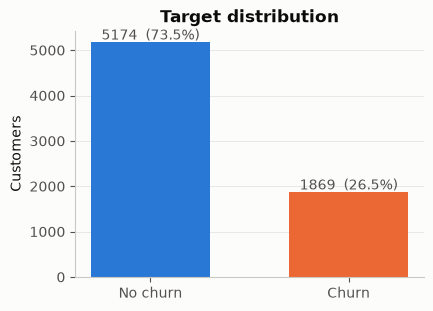

In [7]:
counts = df["Churn"].value_counts().sort_index()
print(counts, "\nchurn rate = %.3f" % df["Churn"].mean())
fig, ax = plt.subplots(figsize=(4.5, 3.2))
bars = ax.bar(["No churn", "Churn"], counts.values, color=[CLASS_COLORS[0], CLASS_COLORS[1]], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v}  ({v / counts.sum():.1%})", ha="center", color=MUTED)
ax.set(title="Target distribution", ylabel="Customers"); ax.grid(axis="x", visible=False)
save(fig, "target_distribution"); plt.show()

About 26.5% of customers churn, a moderate **~2.8 : 1 imbalance**. A model that predicts "no churn" for everyone already gets
~73.5% accuracy, so accuracy on its own is a weak metric here. Later sections focus on recall, precision, F1 and ROC-AUC.

## 5. Numerical distributions (by churn)

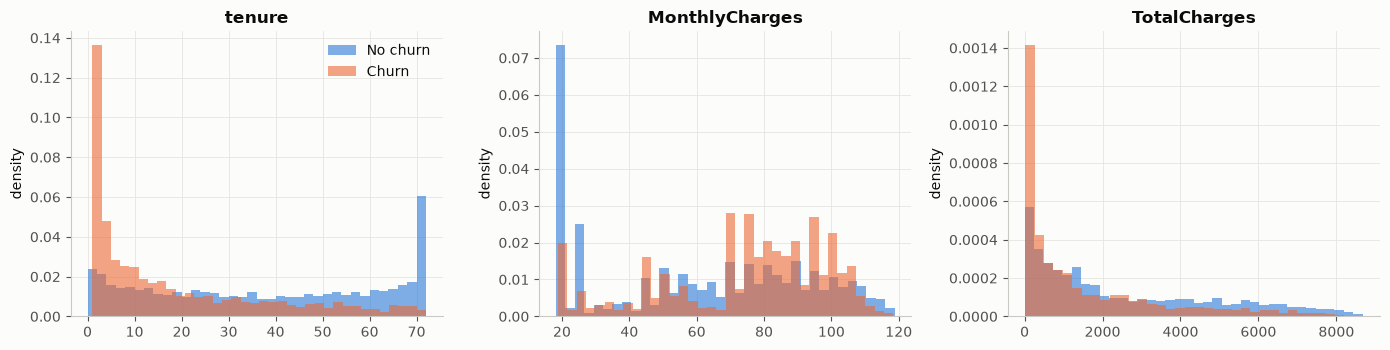

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.425,1679.525
1,10.0,79.650,703.550


In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, num_cols):
    for cls, label in [(0, "No churn"), (1, "Churn")]:
        ax.hist(df.loc[df.Churn == cls, col], bins=36, alpha=0.6, color=CLASS_COLORS[cls], label=label, density=True)
    ax.set(title=col, ylabel="density")
axes[0].legend()
fig.tight_layout(); save(fig, "numerical_distributions"); plt.show()
df.groupby("Churn")[num_cols].median()

* **tenure**: churners are concentrated in the first months (median 10 vs 38 months). Retained customers show a spike at 72,
  which is the dataset's maximum tenure.
* **MonthlyCharges**: churners skew towards higher bills (median ≈ 80 vs 64).
* **TotalCharges** is heavily right-skewed. It is lower for churners mainly because they have shorter tenure.

## 6. Churn vs contract, payment method and internet service

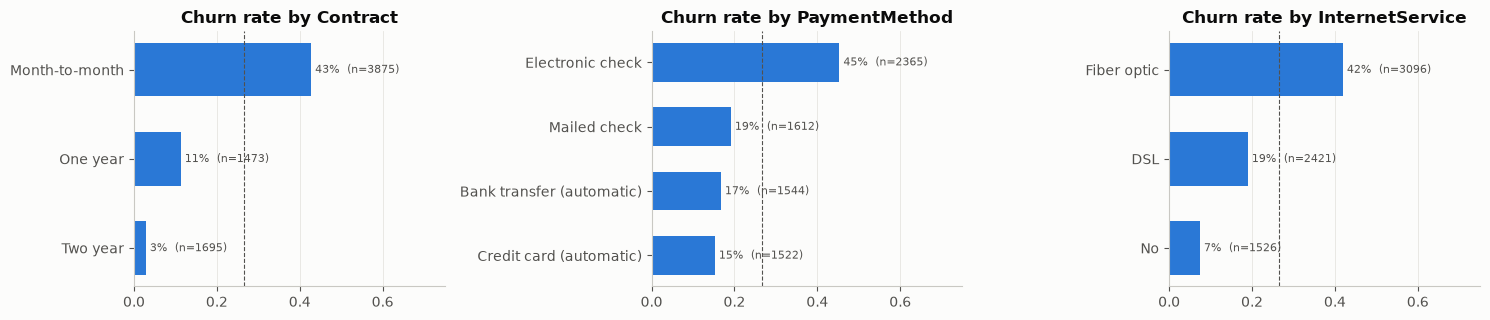

In [9]:
def churn_rate_plot(cols, name, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        rate = df.groupby(col)["Churn"].agg(["mean", "size"]).sort_values("mean")
        ax.barh(rate.index.astype(str), rate["mean"], color=PALETTE[0], height=0.6)
        for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
            ax.text(m + 0.01, i, f"{m:.0%}  (n={n})", va="center", fontsize=8, color=MUTED)
        ax.axvline(df.Churn.mean(), color=MUTED, ls="--", lw=0.8)
        ax.set(title=f"Churn rate by {col}", xlim=(0, max(0.75, rate['mean'].max() + 0.2)))
        ax.grid(axis="y", visible=False)
    for ax in axes[len(cols):]:
        ax.remove()
    fig.tight_layout(); save(fig, name); plt.show()

churn_rate_plot(["Contract", "PaymentMethod", "InternetService"], "churn_by_account")

In [10]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index").round(3)

Churn,0,1
Contract,,
Month-to-month,0.573,0.427
One year,0.887,0.113
Two year,0.972,0.028


The dashed line is the overall churn rate.

* **Contract** shows the sharpest split: month-to-month ≈ 43% churn, one-year ≈ 11%, two-year ≈ 3%.
* **Payment method**: electronic check ≈ 45% churn, far above the automatic methods and mailed check (15–19%).
* **Internet service**: fibre optic customers churn ≈ 42%, against ≈ 19% for DSL and ≈ 7% for no internet. Fibre is also the
  most expensive service, which links this finding to MonthlyCharges.

## 7. Churn vs tenure and monthly charges

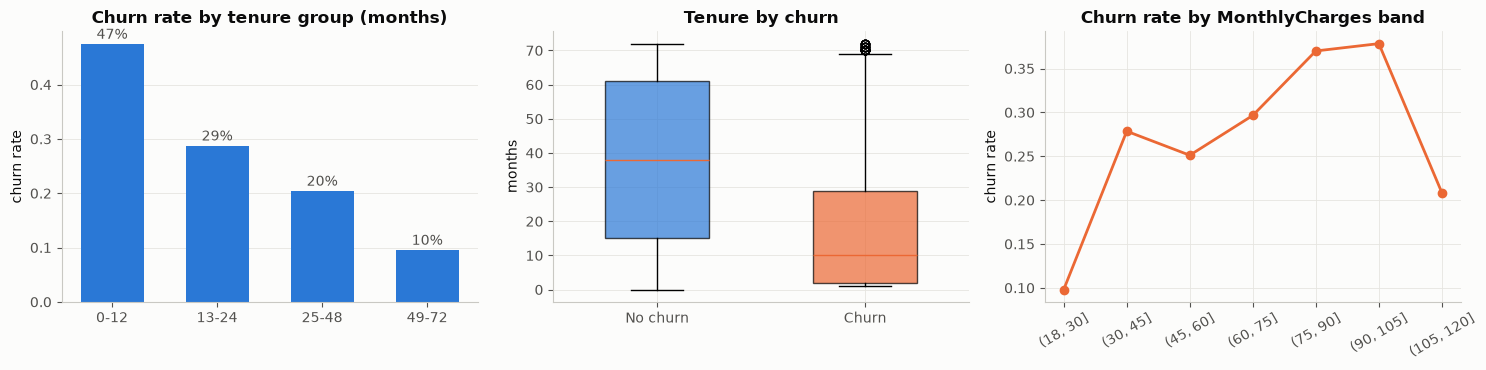

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
tg = df.groupby("tenure_group", observed=True)["Churn"].mean().reindex(["0-12", "13-24", "25-48", "49-72"])
axes[0].bar(tg.index, tg.values, color=PALETTE[0], width=0.6)
for i, v in enumerate(tg.values):
    axes[0].text(i, v + 0.01, f"{v:.0%}", ha="center", color=MUTED)
axes[0].set(title="Churn rate by tenure group (months)", ylabel="churn rate"); axes[0].grid(axis="x", visible=False)

data_box = [df.loc[df.Churn == c, "tenure"] for c in (0, 1)]
bp = axes[1].boxplot(data_box, tick_labels=["No churn", "Churn"], patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], (0, 1)):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_alpha(0.7)
axes[1].set(title="Tenure by churn", ylabel="months")

mc_bins = pd.cut(df["MonthlyCharges"], bins=[18, 30, 45, 60, 75, 90, 105, 120])
mc = df.groupby(mc_bins, observed=True)["Churn"].mean()
axes[2].plot([str(i) for i in mc.index], mc.values, marker="o", color=PALETTE[1])
axes[2].set(title="Churn rate by MonthlyCharges band", ylabel="churn rate")
axes[2].tick_params(axis="x", rotation=30)
fig.tight_layout(); save(fig, "churn_vs_tenure_monthly"); plt.show()

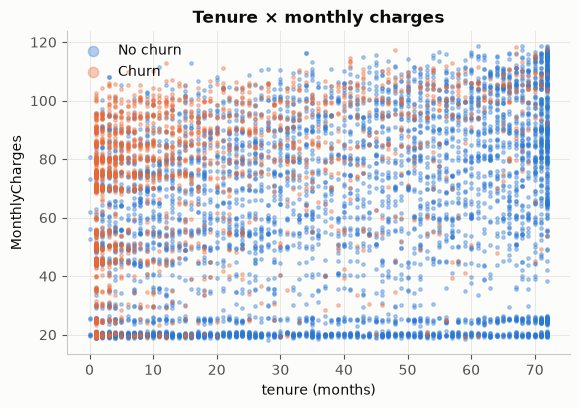

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for cls, label in [(0, "No churn"), (1, "Churn")]:
    sub = df[df.Churn == cls]
    ax.scatter(sub["tenure"], sub["MonthlyCharges"], s=6, alpha=0.35, color=CLASS_COLORS[cls], label=label)
ax.set(xlabel="tenure (months)", ylabel="MonthlyCharges", title="Tenure × monthly charges")
ax.legend(markerscale=3)
save(fig, "tenure_vs_monthly_scatter"); plt.show()

Churn falls steadily with tenure, from ≈ 47% in year one to ≈ 10% after four years. It is lowest (≈ 10%) for the cheapest plans
(≤ 30, mostly phone-only), peaks at ≈ 37–38% in the 75–105 band, and **drops** to ≈ 21% for the most expensive plans (> 105).
Those are typically long-tenure customers with full service bundles, so the relationship is not monotonic. The scatter plot puts the highest-risk group at **short tenure combined with high monthly charges**, which is
mostly new fibre-optic month-to-month customers.

## 8. Demographics

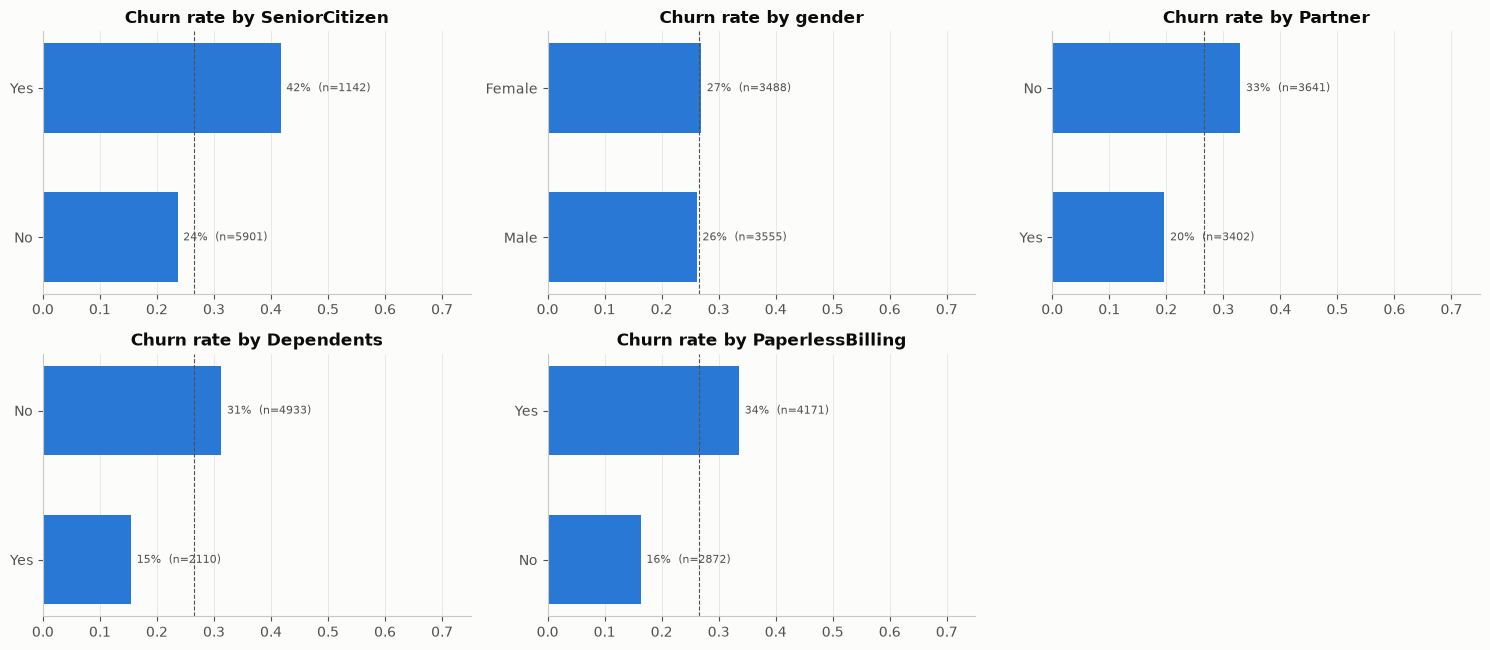

In [13]:
churn_rate_plot(["SeniorCitizen", "gender", "Partner", "Dependents", "PaperlessBilling"], "churn_by_demographics")

* **gender**: no difference (≈ 26–27% for both), so it is unlikely to be a useful predictor.
* **SeniorCitizen**: ≈ 42% vs ≈ 24%, although seniors make up only 16% of customers.
* **Partner / Dependents**: customers with no partner or no dependents churn more (≈ 33% vs ≈ 20%, ≈ 31% vs ≈ 15%).
* **PaperlessBilling**: ≈ 34% vs ≈ 16%.

## 9. Service add-ons

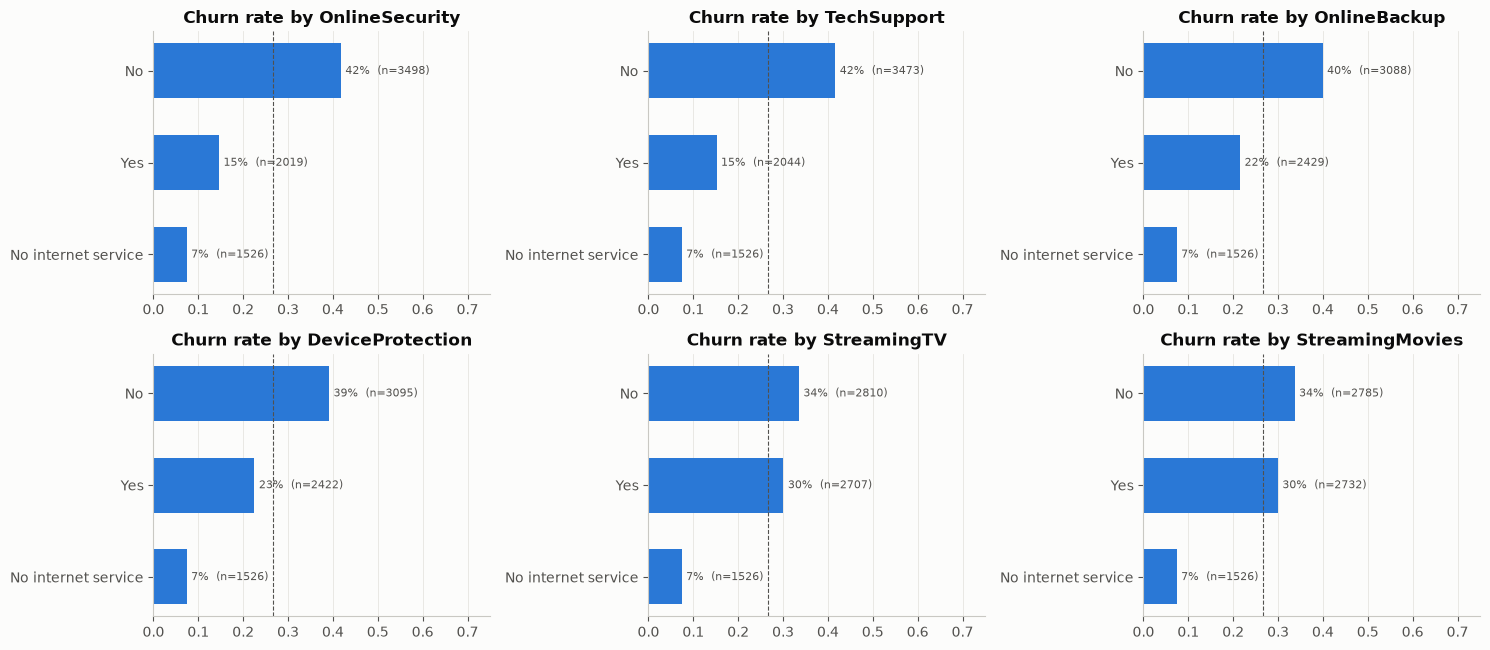

In [14]:
churn_rate_plot(["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"],
                "churn_by_services")

Among internet customers, those **without** OnlineSecurity or TechSupport churn at ≈ 42%, against ≈ 15% for those who have them.
Streaming add-ons make only a small difference (≈ 30% with vs ≈ 34% without).

## 10. Correlation matrix (numerical variables)

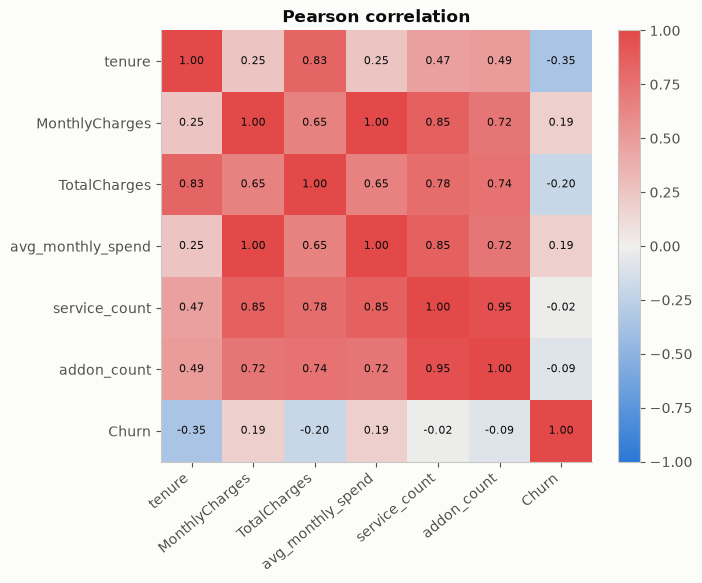

tenure              -0.352229
TotalCharges        -0.198324
addon_count         -0.087698
service_count       -0.019375
avg_monthly_spend    0.192531
MonthlyCharges       0.193356
Name: Churn, dtype: float64

In [15]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "service_count", "addon_count", "Churn"]
corr = df[corr_cols].corr()
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=40, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Pearson correlation")
save(fig, "correlation_matrix"); plt.show()
corr["Churn"].drop("Churn").sort_values()

* `TotalCharges` is strongly driven by `tenure` (r ≈ 0.83) and by `MonthlyCharges`, because it is roughly their product.
* `avg_monthly_spend` is almost the same variable as `MonthlyCharges` (r ≈ 0.996). That is expected, and the feature is
  documented as near-redundant (see below).
* `service_count` correlates strongly with `MonthlyCharges` (r ≈ 0.85), since every extra service adds to the bill.
* `Churn` correlates negatively with tenure (−0.35) and positively with MonthlyCharges (+0.19). Pearson correlation with a
  binary target only captures linear association.

## 11. Engineered features — sanity check

| Feature | Definition | Rationale |
|---|---|---|
| `tenure_group` | tenure binned 0-12 / 13-24 / 25-48 / 49-72 months | churn is non-linear in tenure (steep in year 1) |
| `avg_monthly_spend` | TotalCharges / tenure (MonthlyCharges when tenure = 0) | well-defined historical average bill; differs from MonthlyCharges when the price or plan changed |
| `service_count` | number of the 9 services held (phone, multi-line, internet, 6 add-ons) | product engagement / switching cost |
| `addon_count` | number of the 6 internet add-ons | depth of the bundle beyond base connectivity |

All four are deterministic per-row transforms with no fitted statistics, so creating them before the split cannot leak
information.

In [16]:
diff = df["MonthlyCharges"] - df["avg_monthly_spend"]
print("corr(MonthlyCharges, avg_monthly_spend) = %.4f" % df[["MonthlyCharges", "avg_monthly_spend"]].corr().iloc[0, 1])
print("|MonthlyCharges - avg_monthly_spend|: median %.2f, 95th pct %.2f" % (diff.abs().median(), diff.abs().quantile(0.95)))
print()
print(df.groupby("service_count")["Churn"].agg(["mean", "size"]).round(3).T)
print(df.groupby("addon_count")["Churn"].agg(["mean", "size"]).round(3).T)

corr(MonthlyCharges, avg_monthly_spend) = 0.9962
|MonthlyCharges - avg_monthly_spend|: median 1.15, 95th pct 5.47

service_count         1       2        3        4        5        6        7        8        9
mean              0.109    0.31    0.449    0.365    0.313    0.256    0.225    0.124    0.053
size           1264.000  859.00  846.000  965.000  922.000  908.000  676.000  395.000  208.000
addon_count         0        1         2         3        4        5        6
mean            0.214    0.458     0.358     0.274    0.223    0.124    0.053
size         2219.000  966.000  1033.000  1118.000  852.000  571.000  284.000


`service_count` is **not monotonic**. Customers with one service (mostly phone-only, no internet) churn at ≈ 11%, churn peaks at
≈ 45% for three services, and then falls steadily to ≈ 5% for customers with all nine. `addon_count` follows a similar shape.
The bare internet subscription is the risky profile, and each extra add-on is associated with lower churn. Tree models can use
this non-monotonic shape directly. Logistic regression gets the same information from the individual service columns.

**Takeaways for modelling**

1. The imbalance is moderate (26.5% positive). Measure it, then compare class weighting, SMOTE (inside the training folds only)
   and threshold adjustment.
2. The strongest univariate signals are contract type, tenure, internet service type (fibre), payment by electronic check,
   and the absence of security or tech-support add-ons.
3. `avg_monthly_spend` adds little beyond `MonthlyCharges` (r ≈ 0.996). It is kept because it is cheap and well-defined, and
   the permutation-importance results in notebook 02 confirm that it contributes almost nothing.
4. `gender` looks uninformative.